In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [2]:
df = pd.read_csv("listings.csv")

In [3]:
print(df.shape)

(29918, 90)


In [4]:
print(df.head())

                    id                                       listing_url  \
0  1352055619826961511  https://www.airbnb.com/rooms/1352055619826961511   
1  1215930899551057941  https://www.airbnb.com/rooms/1215930899551057941   
2  1203866180302079266  https://www.airbnb.com/rooms/1203866180302079266   
3             15310580             https://www.airbnb.com/rooms/15310580   
4             32842295             https://www.airbnb.com/rooms/32842295   

        scrape_id last_scraped           source  \
0  20260914002229   2026-09-14              NaN   
1  20260914002229   2026-09-14              NaN   
2  20260914002229   2026-09-15              NaN   
3  20260914002229   2026-09-15  previous scrape   
4  20260914002229   2026-09-15  previous scrape   

                                  name  \
0                  New 3 bed, 1.5 bath   
1                    Queens apartament   
2        Luxury Meets Comfort Stay NYC   
3          Nice apartment in Gramercy.   
4  Beautiful bedroom and f

In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 29918 entries, 0 to 29917
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29918 non-null  int64  
 1   listing_url                                   29918 non-null  str    
 2   scrape_id                                     29918 non-null  int64  
 3   last_scraped                                  29918 non-null  str    
 4   source                                        8906 non-null   str    
 5   name                                          29917 non-null  str    
 6   description                                   29772 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29918 non-null  str    
 9   host_id                                       29918 non-null  int64  
 1

In [7]:
df.describe()

,id,scrape_id,neighborhood_overview,host_id,host_profile_id,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,2.991800e+04,2.991800e+04,0.0,2.991800e+04,2.991800e+04,0.0,29916.000000,29916.000000,29916.000000,29916.000000,...,21796.000000,21801.000000,21795.000000,21795.000000,0.0,29918.000000,29918.000000,29918.000000,29918.000000,21804.000000
mean,6.395048e+17,2.026091e+13,NaN,1.271907e+16,1.472965e+18,NaN,8.366927,5.446918,6.766212,5.608805,...,4.836138,4.815743,4.746239,4.628602,NaN,51.243064,42.274183,8.073401,0.063607,0.917960
std,6.334679e+17,0.000000e+00,NaN,1.471239e+17,3.639654e+16,NaN,4.107429,3.443849,3.976569,3.418822,...,0.380668,0.432427,0.388730,0.502019,NaN,159.162516,157.489040,33.565657,0.823169,2.496574
min,2.539000e+03,2.026091e+13,NaN,1.678000e+03,1.462506e+18,NaN,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.010000
25%,3.044420e+07,2.026091e+13,NaN,2.097116e+07,1.462889e+18,NaN,5.000000,2.000000,3.000000,2.000000,...,4.820000,4.810000,4.670000,4.520000,NaN,1.000000,0.000000,0.000000,0.000000,0.090000
50%,6.742125e+17,2.026091e+13,NaN,1.074344e+08,1.465587e+18,NaN,9.000000,6.000000,7.000000,6.000000,...,4.950000,4.960000,4.850000,4.750000,NaN,2.000000,1.000000,0.000000,0.000000,0.280000
75%,1.178921e+18,2.026091e+13,NaN,4.012771e+08,1.469710e+18,NaN,12.000000,8.000000,10.000000,8.000000,...,5.000000,5.000000,5.000000,4.920000,NaN,11.000000,3.000000,2.000000,0.000000,0.970000
max,1.773595e+18,2.026091e+13,NaN,1.768961e+18,1.772764e+18,NaN,18.000000,11.000000,15.000000,11.000000,...,5.000000,5.000000,5.000000,5.000000,NaN,889.000000,889.000000,231.000000,19.000000,146.870000


In [8]:
print(df.describe())

                 id     scrape_id  neighborhood_overview       host_id  \
count  2.991800e+04  2.991800e+04                    0.0  2.991800e+04   
mean   6.395048e+17  2.026091e+13                    NaN  1.271907e+16   
std    6.334679e+17  0.000000e+00                    NaN  1.471239e+17   
min    2.539000e+03  2.026091e+13                    NaN  1.678000e+03   
25%    3.044420e+07  2.026091e+13                    NaN  2.097116e+07   
50%    6.742125e+17  2.026091e+13                    NaN  1.074344e+08   
75%    1.178921e+18  2.026091e+13                    NaN  4.012771e+08   
max    1.773595e+18  2.026091e+13                    NaN  1.768961e+18   

       host_profile_id  host_since  hosts_time_as_user_years  \
count     2.991800e+04         0.0              29916.000000   
mean      1.472965e+18         NaN                  8.366927   
std       3.639654e+16         NaN                  4.107429   
min       1.462506e+18         NaN                  0.000000   
25%       1.4

In [9]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

print(missing)

host_since                     29918
neighborhood_overview          29918
host_verifications             29918
host_acceptance_rate           29918
host_neighbourhood             29918
host_total_listings_count      29918
host_thumbnail_url             29918
host_response_time             29918
host_response_rate             29918
neighbourhood                  29918
calendar_updated               29918
instant_bookable               29918
bathrooms                      29918
license                        24791
source                         21012
host_about                     12024
price_quote_price_per_night    10513
price_quote_total_price        10513
estimated_revenue_l365d        10512
price                          10512
review_scores_location          8123
review_scores_value             8123
review_scores_checkin           8122
review_scores_accuracy          8120
review_scores_communication     8117
first_review                    8114
review_scores_cleanliness       8114
r

In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
target = 'price_quote_price_per_night'
# Calculate price statistics
print("Price Statistics:")
print(df[target].describe())

# Calculate percentiles
print("\nPrice Percentiles:")
print(df[target].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))


Price Statistics:
count    19405.000000
mean       310.177969
std        574.106324
min         17.700000
25%        103.690000
50%        182.460000
75%        337.000000
max      31537.820000
Name: price_quote_price_per_night, dtype: float64

Price Percentiles:
0.25     103.690
0.50     182.460
0.75     337.000
0.90     628.964
0.95     880.000
0.99    2000.000
Name: price_quote_price_per_night, dtype: float64


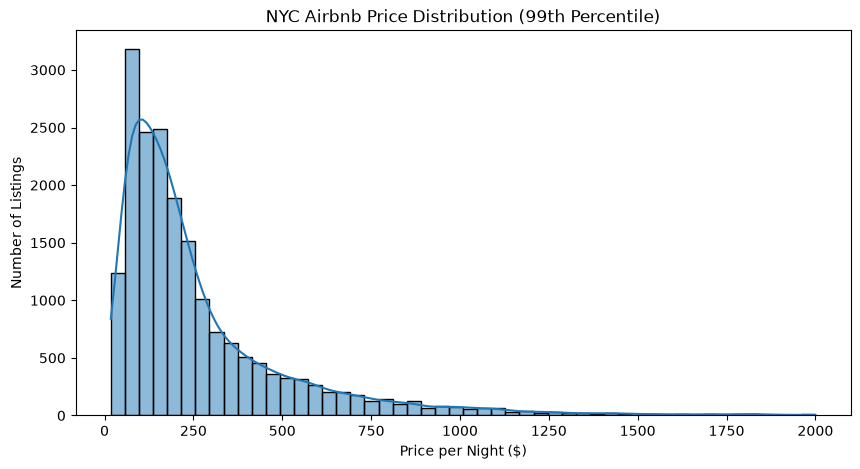

In [14]:

# Remove missing prices
prices = df[target].dropna()

# Calculate 99th percentile
upper_limit = prices.quantile(0.99)

# Filter only for visualization
prices_filtered = prices[prices <= upper_limit]

plt.figure(figsize=(10, 5))

sns.histplot(
    prices_filtered,
    bins=50,
    kde=True
)

plt.title("NYC Airbnb Price Distribution (99th Percentile)")
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")

plt.show()


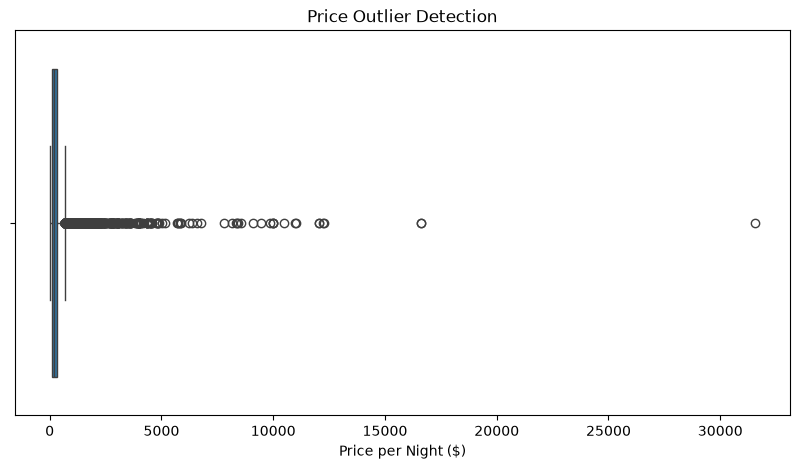

In [15]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df[target])

plt.title("Price Outlier Detection")
plt.xlabel("Price per Night ($)")

plt.show()

In [17]:

# Outlier Detection using IQR

# Calculate Q1 and Q3
Q1 = prices.quantile(0.25)
Q3 = prices.quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Identify potential outliers
outliers = prices[
    (prices < lower_bound) |
    (prices > upper_bound)
]

print("\nTotal Outliers:", len(outliers))

print("Outlier Percentage:",
      (len(outliers) / len(prices)) * 100)

print("\nHighest Prices:")
print(outliers.sort_values(ascending=False).head(10))


Q1: 103.69
Q3: 337.0
IQR: 233.31
Lower Bound: -246.27500000000003
Upper Bound: 686.965

Total Outliers: 1650
Outlier Percentage: 8.502963153826332

Highest Prices:
4684     31537.82
10299    16630.00
9946     16630.00
9747     12279.07
2455     12217.60
15926    12045.03
325      12045.03
23992    11028.87
1952     10988.00
10345    10461.00
Name: price_quote_price_per_night, dtype: float64


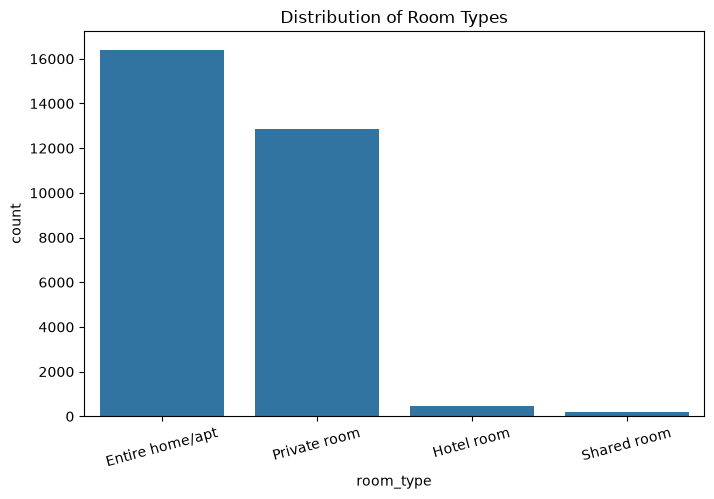

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='room_type',
    order=df['room_type'].value_counts().index
)

plt.title("Distribution of Room Types")
plt.xticks(rotation=15)

plt.show()

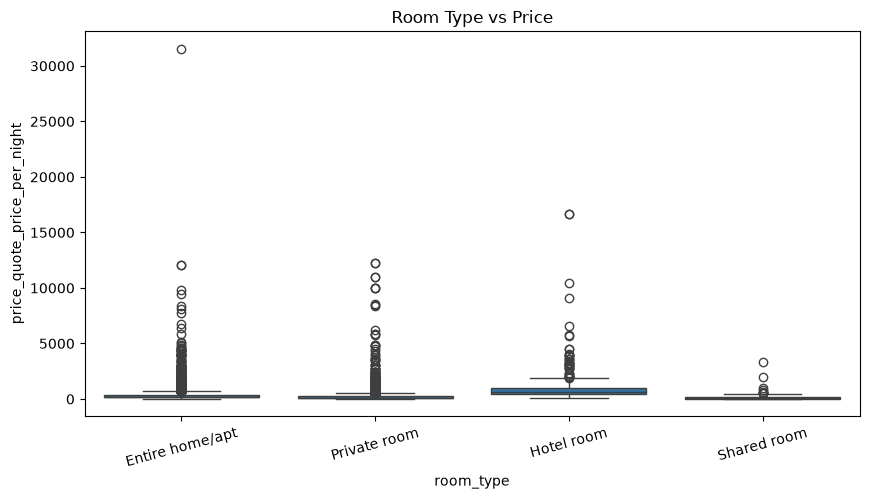

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='room_type',
    y=target
)

plt.title("Room Type vs Price")
plt.xticks(rotation=15)

plt.show()

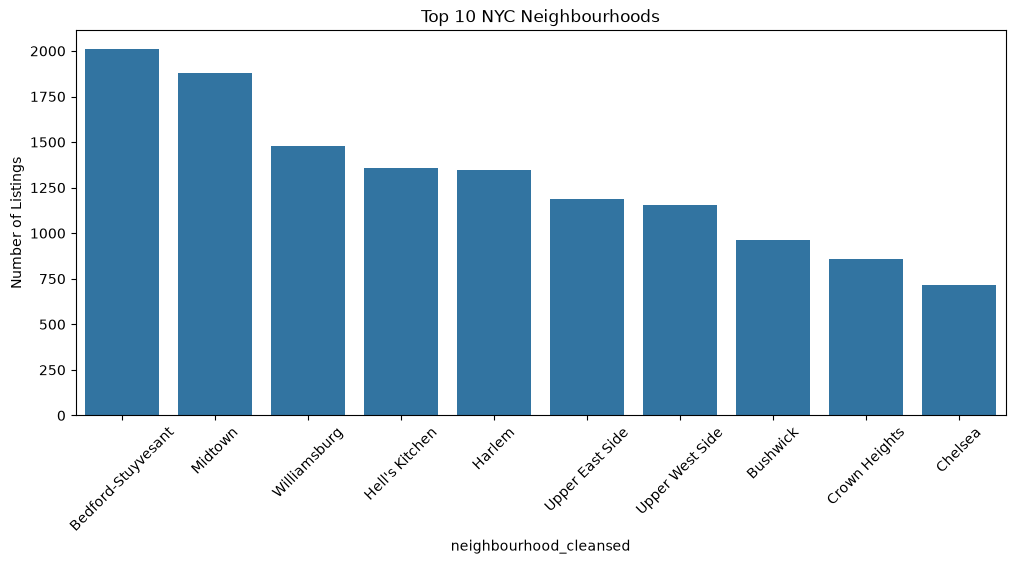

In [22]:
top_neighbourhoods = (
    df['neighbourhood_cleansed']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=top_neighbourhoods.index,
    y=top_neighbourhoods.values
)

plt.title("Top 10 NYC Neighbourhoods")
plt.xticks(rotation=45)
plt.ylabel("Number of Listings")

plt.show()

In [29]:

# Neighbourhood vs Price Analysis

neighbourhood_prices = (
    df.groupby('neighbourhood_cleansed')
    .agg(
        median_price=(target, 'median'),
        average_price=(target, 'mean'),
        listing_count=(target, 'count')
    )
)

# Consider neighbourhoods with at least 30 listings
neighbourhood_prices = neighbourhood_prices[
    neighbourhood_prices['listing_count'] >= 30
]

# Sort by median price
top_expensive_neighbourhoods = (
    neighbourhood_prices
    .sort_values('median_price', ascending=False)
    .head(10)
)

print("Top 10 Expensive Neighbourhoods:")
print(top_expensive_neighbourhoods)


Top 10 Expensive Neighbourhoods:
                        median_price  average_price  listing_count
neighbourhood_cleansed                                            
Tribeca                      616.500    1334.843014             73
Financial District           580.940     775.807248            327
SoHo                         567.000     607.752394            142
Theater District             538.760     637.978315            273
Flatiron District            509.135     637.929423             52
Midtown                      473.840     630.172597           1421
Greenwich Village            449.000     543.180759             79
West Village                 319.260     525.394911            169
Murray Hill                  296.570     510.714900            351
Chinatown                    296.000     404.717455            165


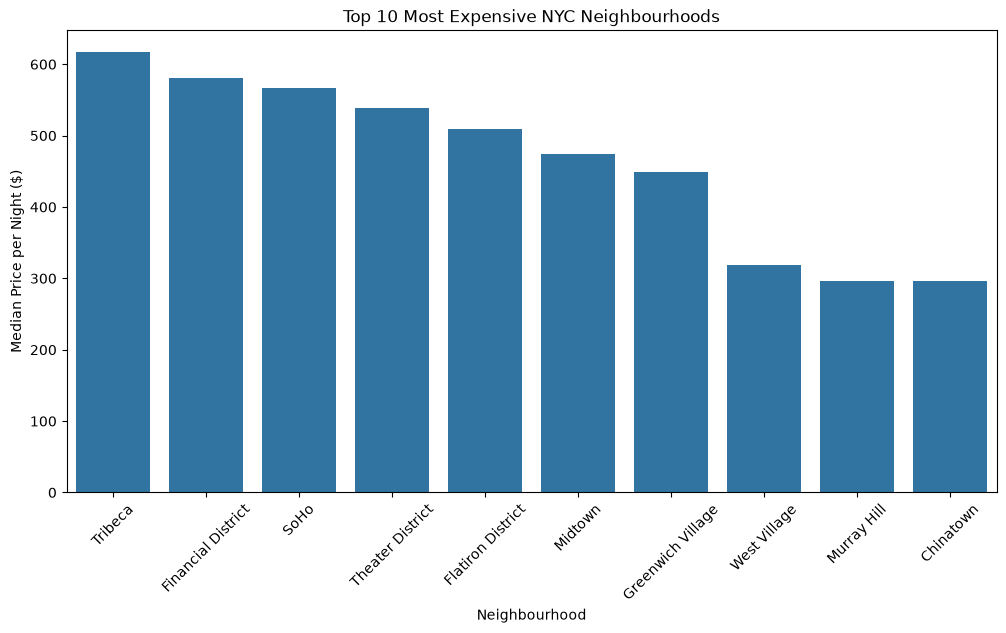

In [30]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_expensive_neighbourhoods.reset_index(),
    x='neighbourhood_cleansed',
    y='median_price'
)

plt.title("Top 10 Most Expensive NYC Neighbourhoods")
plt.xlabel("Neighbourhood")
plt.ylabel("Median Price per Night ($)")
plt.xticks(rotation=45)

plt.show()


Top 10 Affordable Neighbourhoods:
                        median_price  average_price  listing_count
neighbourhood_cleansed                                            
Inwood                        61.120     115.763231             65
Fordham                       62.980      81.852222             36
Mount Hope                    63.625      92.724412             34
Bay Ridge                     70.090     118.313373             83
Elmhurst                      72.680      91.295200            125
Woodside                      74.745     121.336418            134
Cypress Hills                 83.980     139.730507            138
Borough Park                  86.350     132.132812             32
Woodhaven                     87.905     110.066000             60
Washington Heights            88.630     120.353700            200


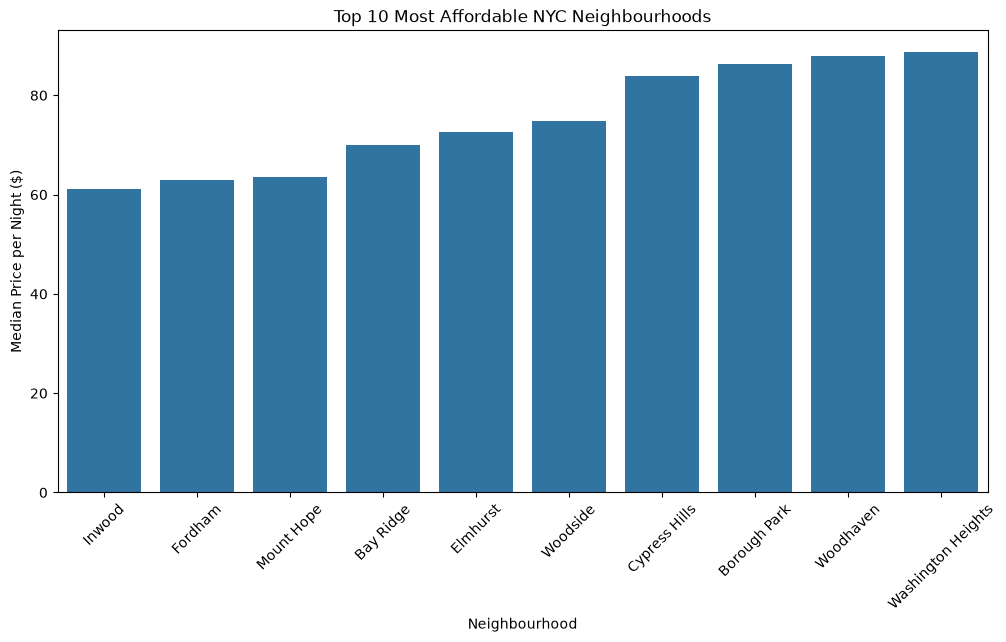

In [31]:

# Top 10 affordable neighbourhoods

affordable_neighbourhoods = (
    neighbourhood_prices
    .sort_values('median_price', ascending=True)
    .head(10)
)

print("Top 10 Affordable Neighbourhoods:")
print(affordable_neighbourhoods)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=affordable_neighbourhoods.reset_index(),
    x='neighbourhood_cleansed',
    y='median_price'
)

plt.title("Top 10 Most Affordable NYC Neighbourhoods")
plt.xlabel("Neighbourhood")
plt.ylabel("Median Price per Night ($)")
plt.xticks(rotation=45)

plt.show()


In [32]:
empty_columns = df.columns[df.isnull().all()]

print("Empty columns:", list(empty_columns))

df = df.drop(columns=empty_columns)

print("Updated Shape:", df.shape)

Empty columns: []
Updated Shape: (19405, 77)


In [33]:
df.drop_duplicates(inplace=True)

print(df.shape)

(19405, 77)


C:\Users\ayush\AppData\Local\Temp\ipykernel_8148\2303767661.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [ ]:
print("Missing prices:", df[target].isnull().sum())

df = df.dropna(subset=[target]).copy()

Missing prices: 10513


In [26]:
df = df[df[target] > 0].copy()

print(df.shape)

(19405, 77)


In [27]:
print(
    df.nlargest(
        20,
        target
    )[['name', 'room_type', 'neighbourhood_cleansed', target]]
)

                                                    name        room_type  \
4684                        260 West Broadway, Unit 1/2C  Entire home/apt   
9946   Opulent Midtown Retreat with White-Gloved Service       Hotel room   
10299  Presidential Suite Park View King Bed, The Pierre       Hotel room   
9747                 Sunny Luxury Bedroom Guest Bathroom     Private room   
2455                 Enormous Chrysler-View Bedroom/Bath     Private room   
325                                   North Gallery Café  Entire home/apt   
15926           Eighth House, State of the Art NYC Venue  Entire home/apt   
23992  WELCOME HOME 15 MINUTES  TO MANHATTAN  BOOK TODAY     Private room   
1952         King + Twin Suite In The Heart of Manhattan     Private room   
10345    Chic Historic Hotel Steps from 5th Avenue Shops       Hotel room   
15483        Paper Factory, Superior Room w/ Double Beds     Private room   
17016                         Paper Factory, Deluxe King     Private room   

In [28]:
print(df[['price', 'price_quote_raw', target]].head(10))

      price                                    price_quote_raw  \
1   $164.55  {"quote": {"taxes": null, "currency": "USD", "...   
7   $236.00  {"quote": {"taxes": null, "currency": "USD", "...   
8   $143.47  {"quote": {"taxes": null, "currency": "USD", "...   
9   $102.97  {"quote": {"taxes": null, "currency": "USD", "...   
10  $137.70  {"quote": {"taxes": null, "currency": "USD", "...   
11  $152.29  {"quote": {"taxes": null, "currency": "USD", "...   
12   $89.37  {"quote": {"taxes": null, "currency": "USD", "...   
13  $135.17  {"quote": {"taxes": null, "currency": "USD", "...   
14  $109.36  {"quote": {"taxes": null, "currency": "USD", "...   
15  $109.88  {"quote": {"taxes": null, "currency": "USD", "...   

    price_quote_price_per_night  
1                        164.55  
7                        236.00  
8                        143.47  
9                        102.97  
10                       137.70  
11                       152.29  
12                        89.37  
1

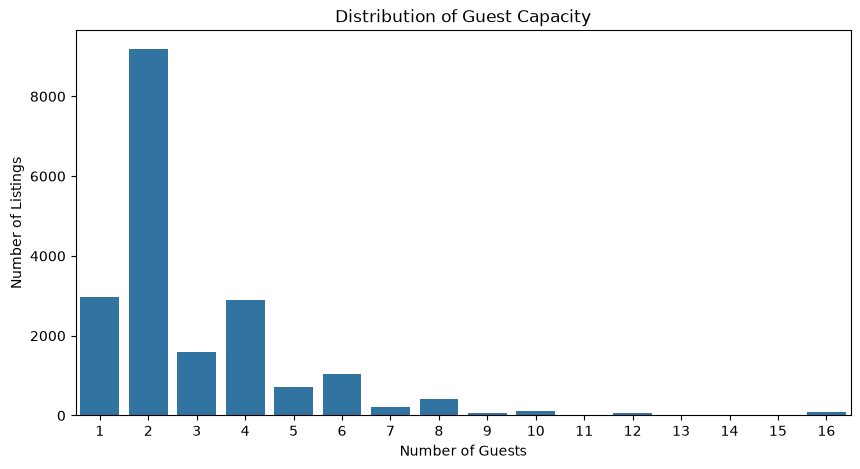

In [34]:
# Distribution of guest capacity

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='accommodates'
)

plt.title("Distribution of Guest Capacity")
plt.xlabel("Number of Guests")
plt.ylabel("Number of Listings")

plt.show()

In [35]:
# Guest capacity vs median price

guest_prices = (
    df.groupby('accommodates')
    .agg(
        median_price=(target, 'median'),
        listing_count=(target, 'count')
    )
)

# Keep groups with at least 30 listings
guest_prices = guest_prices[
    guest_prices['listing_count'] >= 30
]

print(guest_prices)

              median_price  listing_count
accommodates                             
1                   73.000           2973
2                  170.000           9192
3                  204.730           1598
4                  239.180           2890
5                  271.400            714
6                  343.570           1029
7                  374.000            203
8                  515.985            402
9                  424.240             65
10                 550.750            114
12                 903.000             75
16                1288.285             98


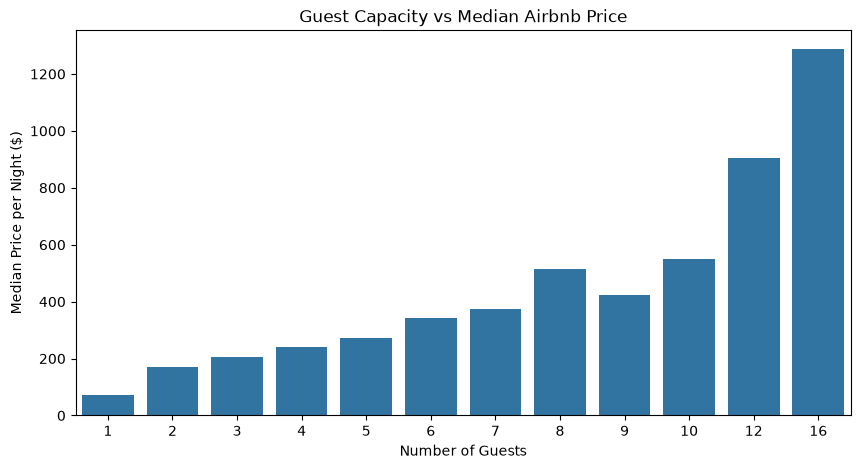

In [36]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=guest_prices.reset_index(),
    x='accommodates',
    y='median_price'
)

plt.title("Guest Capacity vs Median Airbnb Price")
plt.xlabel("Number of Guests")
plt.ylabel("Median Price per Night ($)")

plt.show()

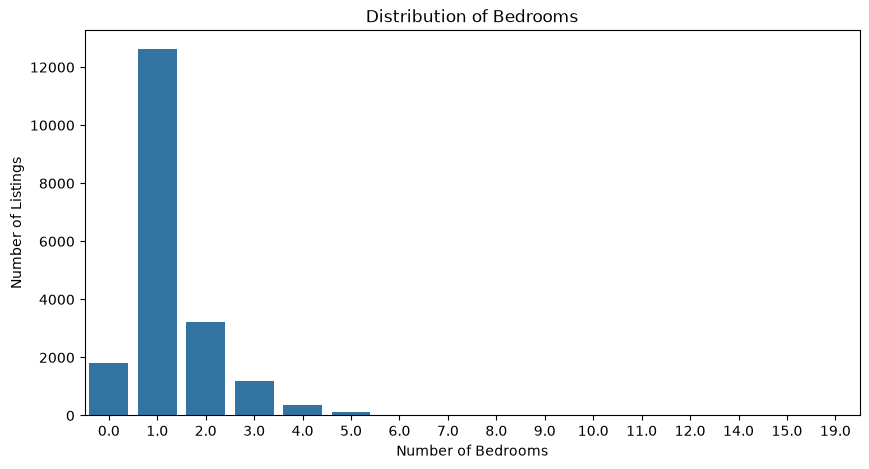

In [37]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='bedrooms'
)

plt.title("Distribution of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Number of Listings")

plt.show()

In [38]:
bedroom_prices = (
    df.groupby('bedrooms')
    .agg(
        median_price=(target, 'median'),
        listing_count=(target, 'count')
    )
)

# Keep groups with at least 30 listings
bedroom_prices = bedroom_prices[
    bedroom_prices['listing_count'] >= 30
]

print("Bedrooms vs Median Price:")
print(bedroom_prices)

Bedrooms vs Median Price:
          median_price  listing_count
bedrooms                             
0.0             177.55           1801
1.0             150.81          12632
2.0             239.67           3205
3.0             321.00           1197
4.0             483.66            360
5.0             390.47            120
6.0             704.67             31


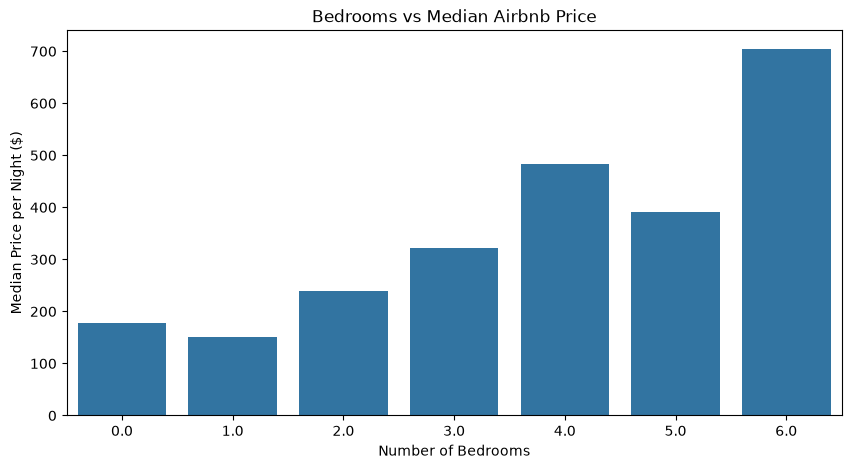

In [39]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=bedroom_prices.reset_index(),
    x='bedrooms',
    y='median_price'
)

plt.title("Bedrooms vs Median Airbnb Price")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Median Price per Night ($)")

plt.show()

In [40]:
print("Bathrooms Text:")
print(df['bathrooms_text'].value_counts().head(20))

print("\nMissing Values:")
print(df['bathrooms_text'].isnull().sum())

print("\nUnique Values:")
print(df['bathrooms_text'].unique()[:30])

Bathrooms Text:
bathrooms_text
1 bath               8574
1 shared bath        3681
1 private bath       3370
2 baths              1411
2 shared baths        577
1.5 baths             505
1.5 shared baths      327
2.5 baths             193
3 baths               175
0 shared baths        109
0 baths                62
3.5 baths              60
4 baths                43
3 shared baths         32
Half-bath              27
Private half-bath      23
Shared half-bath       21
4 shared baths         20
4.5 baths              20
2.5 shared baths       17
Name: count, dtype: int64

Missing Values:
100

Unique Values:
<StringArray>
[   '1 private bath',     '1 shared bath',            '1 bath',
  'Shared half-bath',         'Half-bath',           '2 baths',
                 nan,           '3 baths',         '1.5 baths',
  '1.5 shared baths',    '0 shared baths',         '3.5 baths',
    '2 shared baths',    '5 shared baths',           '5 baths',
         '2.5 baths',    '4 shared baths',  '2.5 sha

In [42]:

# Convert bathrooms_text into numerical values

import re

def extract_bathrooms(value):

    if pd.isna(value):
        return np.nan

    value = str(value).lower()

    # Handle half-bath cases
    if 'half-bath' in value and not re.search(r'\d', value):
        return 0.5

    # Extract numerical value
    match = re.search(r'\d+(?:\.\d+)?', value)

    if match:
        return float(match.group())

    return np.nan


df['bathrooms_numeric'] = df['bathrooms_text'].apply(
    extract_bathrooms
)

print("Bathroom Conversion:")
print(
    df[['bathrooms_text', 'bathrooms_numeric']].head(20)
)

print("\nBathroom Distribution:")
print(df['bathrooms_numeric'].value_counts().sort_index())

print("\nMissing Bathroom Values:")
print(df['bathrooms_numeric'].isnull().sum())


Bathroom Conversion:
      bathrooms_text  bathrooms_numeric
1     1 private bath                1.0
7      1 shared bath                1.0
8             1 bath                1.0
9      1 shared bath                1.0
10            1 bath                1.0
11            1 bath                1.0
12            1 bath                1.0
13            1 bath                1.0
14     1 shared bath                1.0
15            1 bath                1.0
17     1 shared bath                1.0
19  Shared half-bath                0.5
21         Half-bath                0.5
23            1 bath                1.0
25     1 shared bath                1.0
27           2 baths                2.0
28            1 bath                1.0
29            1 bath                1.0
30            1 bath                1.0
31            1 bath                1.0

Bathroom Distribution:
bathrooms_numeric
0.0       171
0.5        71
1.0     15625
1.5       832
2.0      1996
2.5       210
3.0       211

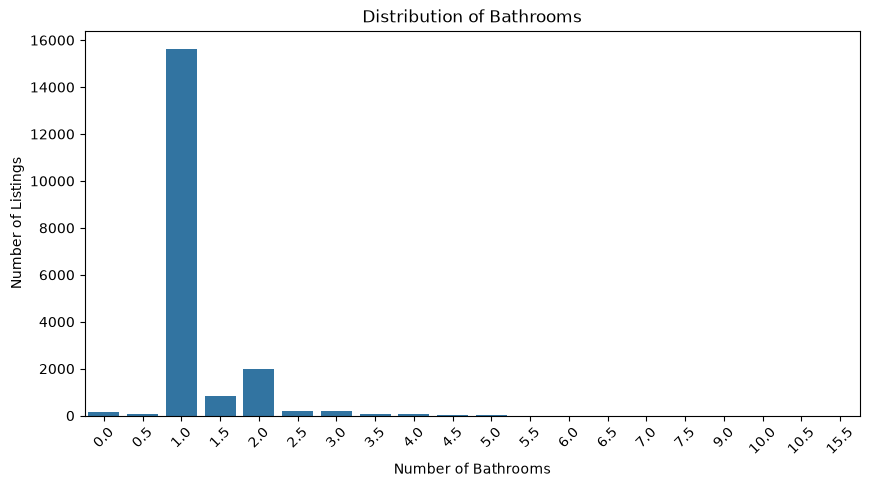

In [43]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='bathrooms_numeric',
    order=sorted(
        df['bathrooms_numeric'].dropna().unique()
    )
)

plt.title("Distribution of Bathrooms")
plt.xlabel("Number of Bathrooms")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)

plt.show()


In [44]:

bathroom_prices = (
    df.groupby('bathrooms_numeric')
    .agg(
        median_price=(target, 'median'),
        listing_count=(target, 'count')
    )
)

# Keep groups with at least 30 listings
bathroom_prices = bathroom_prices[
    bathroom_prices['listing_count'] >= 30
]

print("Bathrooms vs Median Price:")
print(bathroom_prices)


Bathrooms vs Median Price:
                   median_price  listing_count
bathrooms_numeric                             
0.0                      109.07            171
0.5                      116.37             71
1.0                      174.53          15625
1.5                      160.00            832
2.0                      260.99           1996
2.5                      475.00            210
3.0                      527.17            211
3.5                      727.33             67
4.0                      365.96             65


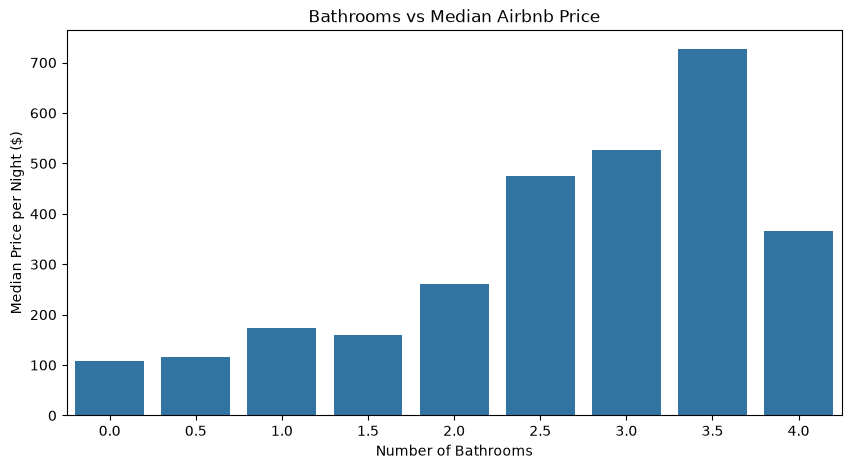

In [45]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=bathroom_prices.reset_index(),
    x='bathrooms_numeric',
    y='median_price'
)

plt.title("Bathrooms vs Median Airbnb Price")
plt.xlabel("Number of Bathrooms")
plt.ylabel("Median Price per Night ($)")

plt.show()


In [46]:
# Select numerical columns

numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation with target

correlation = numeric_df.corr()

# Sort features by correlation with price

price_correlation = (
    correlation[target]
    .sort_values(ascending=False)
)

print("Correlation with Price:")
print(price_correlation)

Correlation with Price:
price_quote_price_per_night                     1.000000
price_quote_total_price                         0.633046
accommodates                                    0.320506
bathrooms_numeric                               0.266979
beds                                            0.233290
bedrooms                                        0.231775
estimated_revenue_l365d                         0.204091
host_listings_count                             0.178817
availability_30                                 0.110026
availability_60                                 0.098015
id                                              0.097742
availability_90                                 0.086416
availability_eoy                                0.081975
review_scores_location                          0.079972
reviews_per_month                               0.078265
calculated_host_listings_count                  0.071301
host_profile_id                                 0.060348
latitud

price_quote_price_per_night    1.000000
accommodates                   0.320506
bathrooms_numeric              0.266979
bedrooms                       0.231775
latitude                       0.059378
longitude                     -0.157017
Name: price_quote_price_per_night, dtype: float64


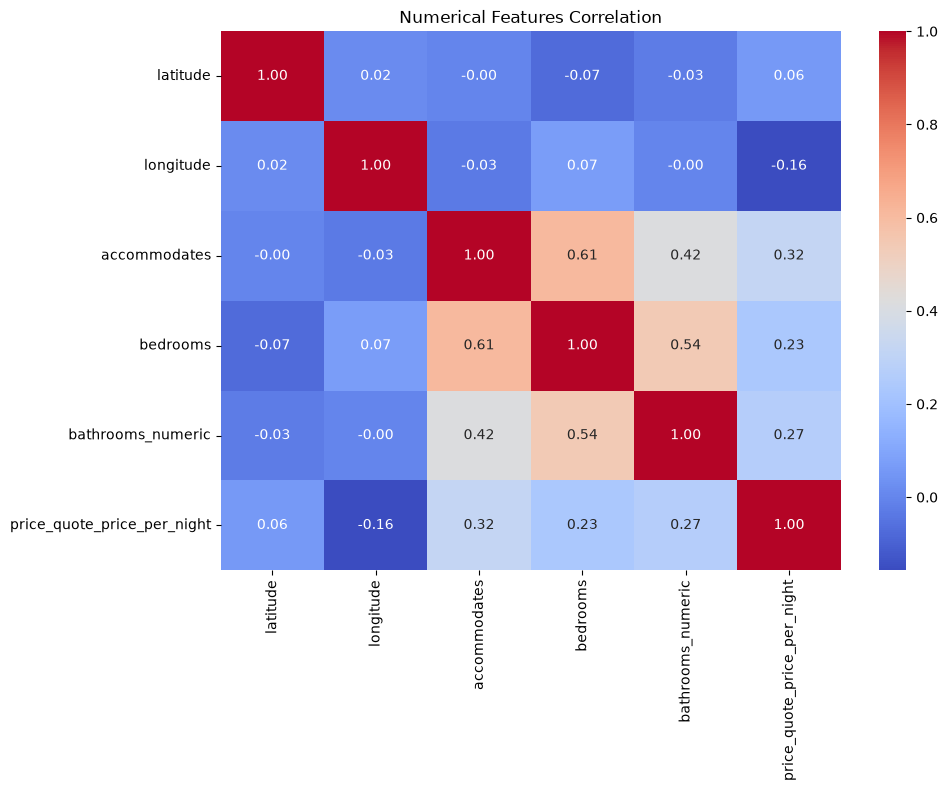

In [48]:
numeric_features = [
    'latitude',
    'longitude',
    'accommodates',
    'bedrooms',
    'bathrooms_numeric',
    target
]

correlation = df[numeric_features].corr()

print(correlation[target].sort_values(ascending=False))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Numerical Features Correlation")
plt.show()

In [51]:
features = [
    'neighbourhood_cleansed',
    'room_type',
    'latitude',
    'longitude',
    'accommodates',
    'bedrooms',
    'bathrooms_numeric'
]

target = 'price_quote_price_per_night'

df_model = df[features + [target]].copy()

print("Dataset Shape:", df_model.shape)

print("\nData Types:")
print(df_model.dtypes)

print("\nMissing Values:")
print(
    df_model.isnull().sum().sort_values(
        ascending=False
    )
)

print("\nDuplicate Rows:", df_model.duplicated().sum())

Dataset Shape: (19405, 8)

Data Types:
neighbourhood_cleansed             str
room_type                          str
latitude                       float64
longitude                      float64
accommodates                     int64
bedrooms                       float64
bathrooms_numeric              float64
price_quote_price_per_night    float64
dtype: object

Missing Values:
bathrooms_numeric              100
bedrooms                        32
neighbourhood_cleansed           0
room_type                        0
longitude                        0
latitude                         0
accommodates                     0
price_quote_price_per_night      0
dtype: int64

Duplicate Rows: 602


In [50]:
print(df_model.describe())

           latitude     longitude  accommodates      bedrooms  \
count  19405.000000  19405.000000  19405.000000  19373.000000   
mean      40.727535    -73.943554      2.935893      1.295772   
std        0.058943      0.062273      2.097822      0.908787   
min       40.504560    -74.251907      1.000000      0.000000   
25%       40.685070    -73.984250      2.000000      1.000000   
50%       40.730282    -73.954420      2.000000      1.000000   
75%       40.762964    -73.921390      4.000000      2.000000   
max       40.911147    -73.713650     16.000000     19.000000   

       bathrooms_numeric  price_quote_price_per_night  
count       19305.000000                 19405.000000  
mean            1.185392                   310.177969  
std             0.538339                   574.106324  
min             0.000000                    17.700000  
25%             1.000000                   103.690000  
50%             1.000000                   182.460000  
75%             1.0000

In [53]:
print("Total listings:", len(df))

print(
    "Duplicate listing IDs:",
    df['id'].duplicated().sum()
)

print("\nDuplicate listing examples:")

print(
    df[df['id'].duplicated(keep=False)]
    [['id', 'name', target]]
    .head(10)
)

Total listings: 19405
Duplicate listing IDs: 0

Duplicate listing examples:
Empty DataFrame
Columns: [id, name, price_quote_price_per_night]
Index: []


In [54]:
df_model['bedrooms'] = df_model['bedrooms'].fillna(
    df_model['bedrooms'].median()
)

df_model['bathrooms_numeric'] = df_model['bathrooms_numeric'].fillna(
    df_model['bathrooms_numeric'].median()
)

print("Missing values after treatment:")
print(df_model.isnull().sum())

Missing values after treatment:
neighbourhood_cleansed         0
room_type                      0
latitude                       0
longitude                      0
accommodates                   0
bedrooms                       0
bathrooms_numeric              0
price_quote_price_per_night    0
dtype: int64


In [55]:
columns = [
    'bedrooms',
    'bathrooms_numeric',
    'accommodates',
    target
]

for col in columns:
    print(f"\n{col}")
    print(df_model[col].describe(
        percentiles=[0.95, 0.99]
    ))


bedrooms
count    19405.000000
mean         1.295285
std          0.908117
min          0.000000
95%          3.000000
99%          4.000000
max         19.000000
Name: bedrooms, dtype: float64

bathrooms_numeric
count    19405.000000
mean         1.184437
std          0.537115
min          0.000000
95%          2.000000
99%          3.000000
max         15.500000
Name: bathrooms_numeric, dtype: float64

accommodates
count    19405.000000
mean         2.935893
std          2.097822
min          1.000000
95%          7.000000
99%         12.000000
max         16.000000
Name: accommodates, dtype: float64

price_quote_price_per_night
count    19405.000000
mean       310.177969
std        574.106324
min         17.700000
95%        880.000000
99%       2000.000000
max      31537.820000
Name: price_quote_price_per_night, dtype: float64


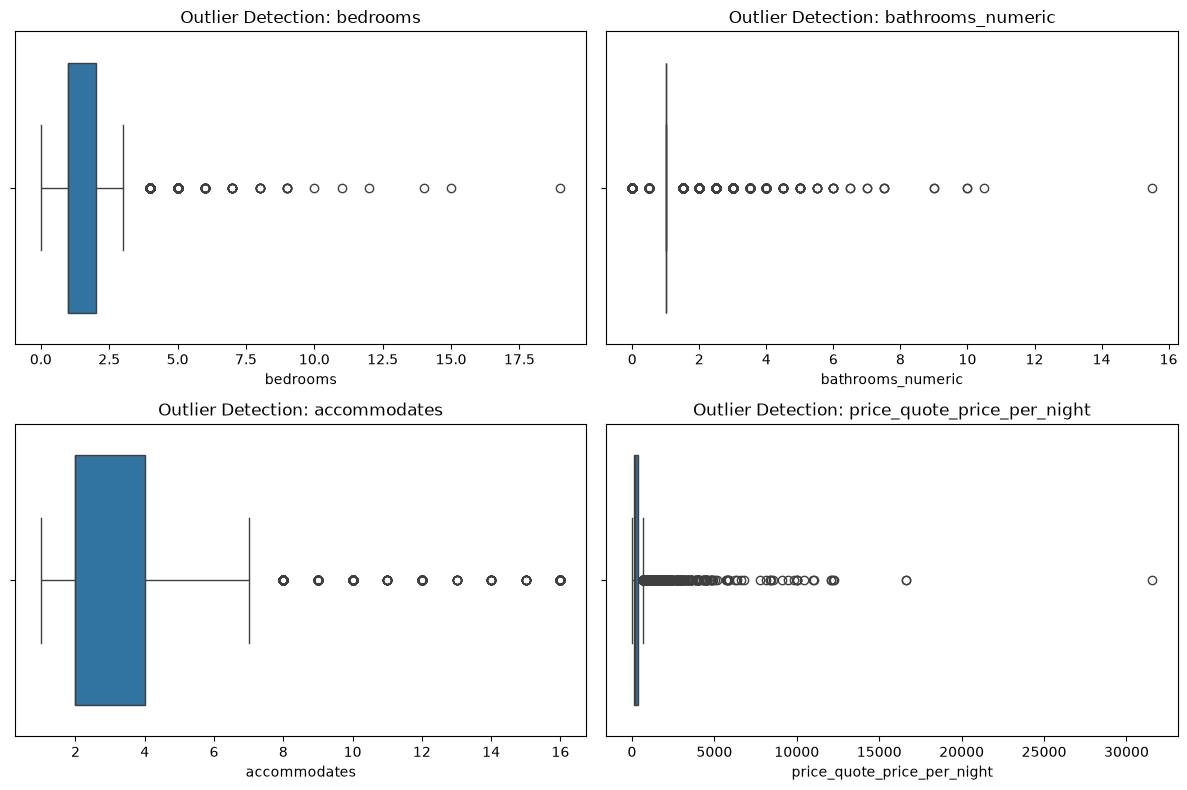

In [56]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(columns, 1):

    plt.subplot(2, 2, i)

    sns.boxplot(x=df_model[col])

    plt.title(f"Outlier Detection: {col}")

plt.tight_layout()
plt.show()

In [57]:
# Top 15 expensive listings

print(
    df.loc[
        df_model[target].nlargest(15).index,
        ['id', 'name', 'room_type',
         'bedrooms', 'bathrooms_text',
         'accommodates', target]
    ].to_string(index=False)
)

                 id                                              name       room_type  bedrooms  bathrooms_text  accommodates  price_quote_price_per_night
1685032623471298360                      260 West Broadway, Unit 1/2C Entire home/apt       7.0       7.5 baths            14                     31537.82
1111666023012679487 Opulent Midtown Retreat with White-Gloved Service      Hotel room       2.0             NaN             5                     16630.00
1111666150326773564 Presidential Suite Park View King Bed, The Pierre      Hotel room       2.0 2 private baths             5                     16630.00
             990529               Sunny Luxury Bedroom Guest Bathroom    Private room       1.0          1 bath             2                     12279.07
            1623431               Enormous Chrysler-View Bedroom/Bath    Private room       1.0          1 bath             2                     12217.60
 830682282357157632                                North Gallery Café 

In [58]:
print("\nListings with more than 6 bedrooms:")

print(
    df_model[df_model['bedrooms'] > 6][
        ['bedrooms', 'bathrooms_numeric',
         'accommodates', target]
    ].to_string(index=False)
)

print("\nListings with more than 4 bathrooms:")

print(
    df_model[df_model['bathrooms_numeric'] > 4][
        ['bedrooms', 'bathrooms_numeric',
         'accommodates', target]
    ].to_string(index=False)
)


Listings with more than 6 bedrooms:
 bedrooms  bathrooms_numeric  accommodates  price_quote_price_per_night
      8.0                3.5            16                      1403.50
      9.0                1.0            16                      1401.00
     12.0                1.0            16                      3244.00
      8.0                5.0            16                      1069.78
      7.0                4.0             1                        63.80
      7.0                7.5            14                     31537.82
      7.0                7.5            16                      5825.89
     14.0               15.5            16                      2133.40
      8.0                4.0            16                      1389.97
      7.0                4.0            14                       314.19
      7.0                3.0             1                        50.70
      7.0                1.0             1                       125.96
      9.0                4.

In [59]:
# Price outliers
price_limit = df_model[target].quantile(0.99)

print("99th Percentile:", price_limit)

print(
    "Listings above $2000:",
    (df_model[target] > 2000).sum()
)

# Bedroom outliers
print(
    "\nListings with bedrooms > 6:",
    (df_model['bedrooms'] > 6).sum()
)

# Bathroom outliers
print(
    "\nListings with bathrooms > 4:",
    (df_model['bathrooms_numeric'] > 4).sum()
)

# Suspicious bedroom and guest capacity combinations
print(
    "\nBedrooms greater than accommodates:"
)

print(
    df_model[
        df_model['bedrooms'] > df_model['accommodates']
    ][[
        'bedrooms',
        'accommodates',
        target
    ]].head(15)
)

99th Percentile: 2000.0
Listings above $2000: 194

Listings with bedrooms > 6: 27

Listings with bathrooms > 4: 57

Bedrooms greater than accommodates:
      bedrooms  accommodates  price_quote_price_per_night
220        3.0             2                       556.00
363        3.0             2                       399.23
416        2.0             1                       158.59
519        3.0             2                       176.63
533        4.0             1                        73.06
534        2.0             1                        61.98
605        4.0             1                        77.20
611        4.0             2                       223.80
614        4.0             2                       620.80
701        5.0             1                        52.00
771        2.0             1                       167.23
805        4.0             1                        78.84
899        5.0             1                       124.54
1315       5.0             1        

In [60]:
# Remove extreme price outliers
price_limit = df[target].quantile(0.99)

df = df[df[target] <= price_limit].copy()

# Remove unusual property sizes
df = df[
    (df['bedrooms'] <= 6) &
    (df['bathrooms_numeric'] <= 4)
].copy()

print("Dataset shape after outlier treatment:", df.shape)

print("Maximum price:", df[target].max())

print("Maximum bedrooms:", df['bedrooms'].max())

print("Maximum bathrooms:", df['bathrooms_numeric'].max())

Dataset shape after outlier treatment: (19060, 78)
Maximum price: 2000.0
Maximum bedrooms: 6.0
Maximum bathrooms: 4.0


In [61]:
# Check unique categories

print("Room Types:")
print(df['room_type'].value_counts())

print("\nTop 15 Neighbourhoods:")
print(df['neighbourhood_cleansed'].value_counts().head(15))

print("\nTotal Unique Neighbourhoods:")
print(df['neighbourhood_cleansed'].nunique())

Room Types:
room_type
Entire home/apt    9951
Private room       8624
Hotel room          332
Shared room         153
Name: count, dtype: int64

Top 15 Neighbourhoods:
neighbourhood_cleansed
Midtown               1382
Bedford-Stuyvesant    1277
Hell's Kitchen         942
Harlem                 912
Upper East Side        790
Upper West Side        695
Williamsburg           664
Bushwick               556
Crown Heights          549
Chelsea                413
East Flatbush          377
Murray Hill            332
East Village           320
East Harlem            318
Lower East Side        317
Name: count, dtype: int64

Total Unique Neighbourhoods:
223


In [62]:

# Separate Features and Target

features = [
    'neighbourhood_cleansed',
    'room_type',
    'latitude',
    'longitude',
    'accommodates',
    'bedrooms',
    'bathrooms_numeric'
]

target = 'price_quote_price_per_night'

X = df[features].copy()
y = df[target].copy()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nCategorical Features:")
print(X.select_dtypes(include=['object', 'str']).columns.tolist())

print("\nNumerical Features:")
print(X.select_dtypes(include=['number']).columns.tolist())


Features Shape: (19060, 7)
Target Shape: (19060,)

Categorical Features:
['neighbourhood_cleansed', 'room_type']

Numerical Features:
['latitude', 'longitude', 'accommodates', 'bedrooms', 'bathrooms_numeric']


In [64]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.29.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.29.0-py3-none-any.whl (501 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ -------------


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (15248, 7)
Testing Data: (3812, 7)


In [66]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [67]:
numeric_features = [
    'latitude',
    'longitude',
    'accommodates',
    'bedrooms',
    'bathrooms_numeric'
]

categorical_features = [
    'neighbourhood_cleansed',
    'room_type'
]

In [68]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [69]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [70]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Training Data Shape: (15248, 229)
Testing Data Shape: (3812, 229)


In [71]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [72]:
model.fit(X_train_processed, y_train)

print("Linear Regression Model Trained Successfully!")

y_pred = model.predict(X_test_processed)

print("First 10 Predictions:")
print(y_pred[:10])

Linear Regression Model Trained Successfully!
First 10 Predictions:
[204.5400708  157.90684634 477.01257013 142.18296401 124.69591604
 209.69327885 349.02504722  33.62582554  48.31501281 184.86212477]


In [73]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [74]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 131.96149164549084
MSE: 43564.46866969375
RMSE: 208.72103073167722
R2 Score: 0.4088292708429474


In [75]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [76]:
rf_pred = rf_model.predict(X_test_processed)

print("First 10 Random Forest Predictions:")
print(rf_pred[:10])

First 10 Random Forest Predictions:
[374.86285     46.0631     457.67241667 173.52465    181.4065
 150.1688     175.30976799 124.33795    137.4586     154.30635   ]


In [77]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation Results")
print("--------------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Evaluation Results
--------------------------------
MAE: 102.14601020570629
MSE: 32853.28168950248
RMSE: 181.25474252968522
R2 Score: 0.5541802968184403


In [78]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae, rf_mae],
    'RMSE': [rmse, rf_rmse],
    'R2 Score': [r2, rf_r2]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,131.961492,208.721031,0.408829
1,Random Forest,102.146010,181.254743,0.554180


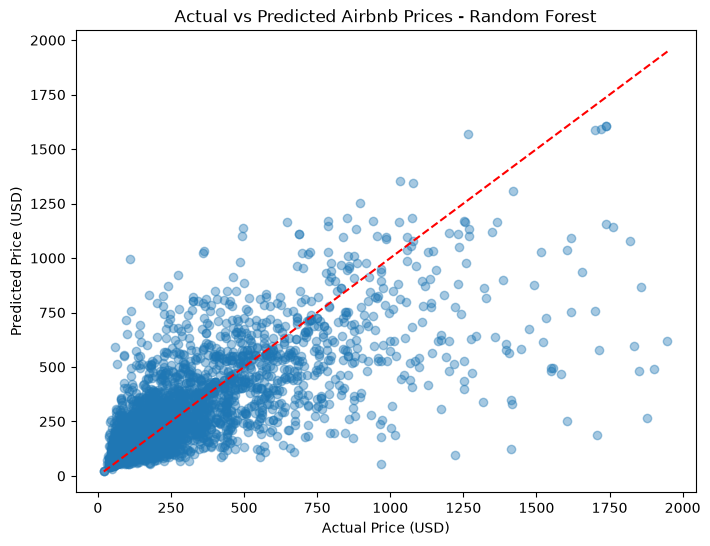

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.4)

plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.title("Actual vs Predicted Airbnb Prices - Random Forest")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [80]:
results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': rf_pred
})

results['Difference'] = (
    results['Actual Price'] - results['Predicted Price']
)

results.head(10)

,Actual Price,Predicted Price,Difference
0,446.00,374.862850,71.137150
1,38.86,46.063100,-7.203100
2,491.00,457.672417,33.327583
3,266.00,173.524650,92.475350
4,174.42,181.406500,-6.986500
5,229.40,150.168800,79.231200
6,156.67,175.309768,-18.639768
7,68.15,124.337950,-56.187950
8,66.12,137.458600,-71.338600
9,78.01,154.306350,-76.296350


In [81]:
feature_names = preprocessor.get_feature_names_out()

importances = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
1,num__longitude,0.339252
0,num__latitude,0.239890
2,num__accommodates,0.164056
4,num__bathrooms_numeric,0.064870
3,num__bedrooms,0.043540
225,cat__room_type_Entire home/apt,0.036956
134,cat__neighbourhood_cleansed_Midtown,0.014084
227,cat__room_type_Private room,0.009075
226,cat__room_type_Hotel room,0.007301
196,cat__neighbourhood_cleansed_Theater District,0.005998


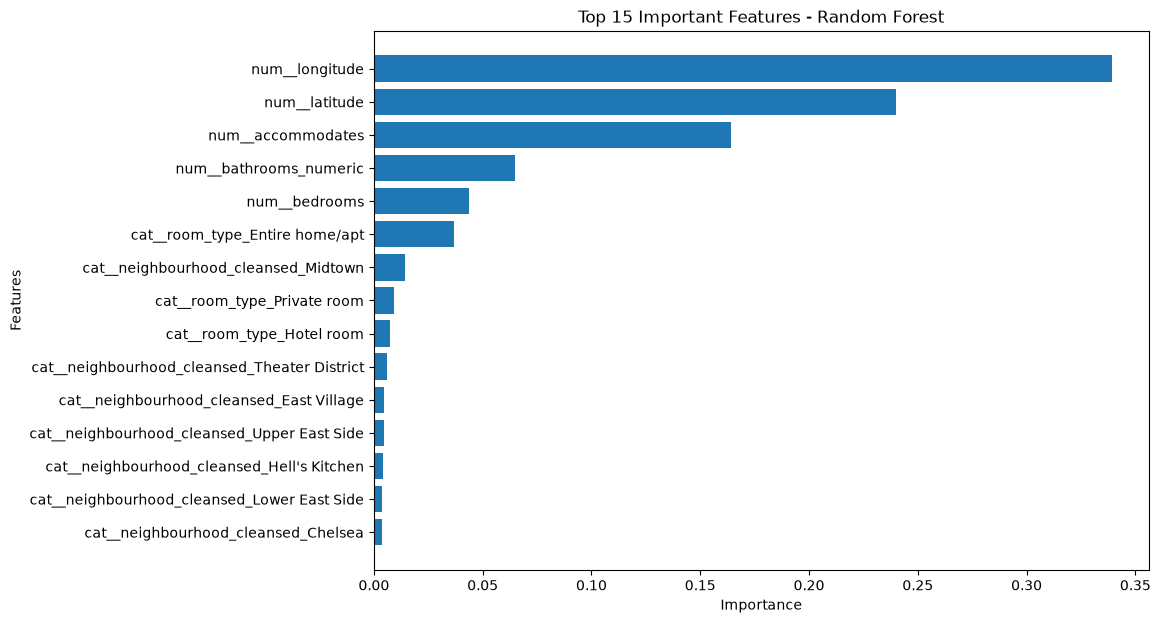

In [82]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Random Forest")

plt.gca().invert_yaxis()

plt.show()

In [83]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [84]:
param_dist = {
    'n_estimators': [200, 300, 400],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 1.0]
}

In [85]:
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_processed, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 1.0], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a

In [86]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV MAE:")
print(-random_search.best_score_)

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 30}

Best CV MAE:
98.78888835359714


In [87]:
best_model = random_search.best_estimator_

tuned_pred = best_model.predict(X_test_processed)

tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_pred)
)
tuned_r2 = r2_score(y_test, tuned_pred)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R2 Score:", tuned_r2)

Tuned Random Forest Results
---------------------------
MAE: 102.77082701968004
RMSE: 180.32665329981552
R2 Score: 0.5587341215438615


In [88]:
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', rf_model)
])

In [90]:
final_pipeline.fit(X_train, y_train)

print("Final Pipeline Trained Successfully!")

Final Pipeline Trained Successfully!


In [91]:
final_predictions = final_pipeline.predict(X_test)

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)
final_r2 = r2_score(y_test, final_predictions)

print("Final Pipeline Results")
print("----------------------")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)

Final Pipeline Results
----------------------
MAE: 102.14601020570629
RMSE: 181.25474252968522
R2 Score: 0.5541802968184403


In [92]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [93]:
import joblib

joblib.dump(
    final_pipeline,
    "airbnb_price_pipeline.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [94]:
loaded_model = joblib.load("airbnb_price_pipeline.pkl")

sample_prediction = loaded_model.predict(X_test.head(5))

print("Predictions from Saved Model:")
print(sample_prediction)

Predictions from Saved Model:
[374.86285     46.0631     457.67241667 173.52465    181.4065    ]
